10.Implementing Self-Organizing Maps (SOM) for Image Compression-
a. Implement Kohonen’s Self-Organizing Map (SOM) for image compression.

b. Train SOM to reduce the number of colors in an image.
c. Display the original and compressed images to analyze quality loss

SOM Training Completed!


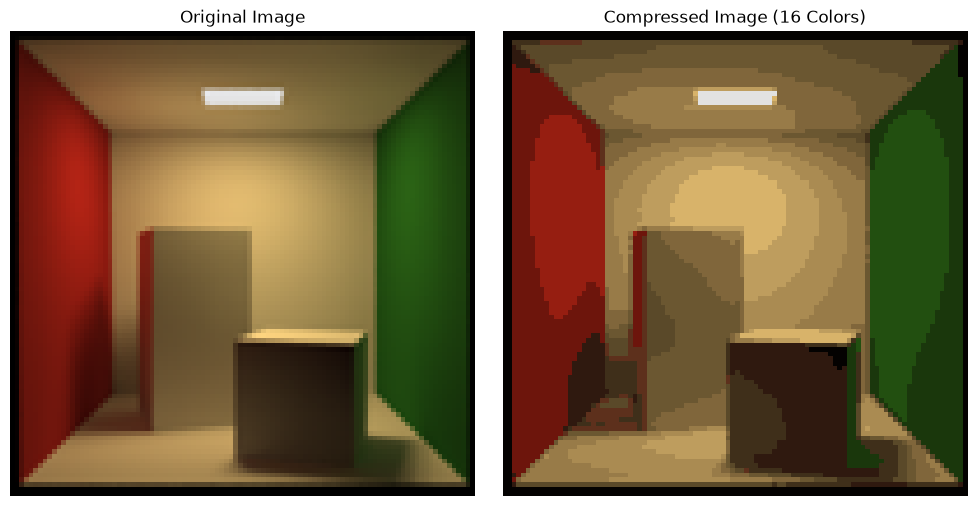


Image Quality Analysis
----------------------
Mean Squared Error (MSE): 45.06216666666667
Peak Signal-to-Noise Ratio (PSNR): 31.592682913505968 dB
Mean Absolute Error (MAE): 4.840566666666667

SOM Image Compression Completed!
Original Image Size: (100, 100)
Number of Colors: 16
Compressed image saved as compressed.jpg


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

np.random.seed(42)

# 1. Load Image
img = Image.open("BOX.png").convert("RGB")
img = img.resize((100, 100))

# 2. Convert Image into RGB Pixels
pixels = np.array(img)
pixels = pixels.reshape(-1, 3).astype(float)

# 3. Initialize SOM
k = 16
weights = np.random.rand(k, 3) * 255

learning_rate = 0.5
radius = k / 2
epochs = 50

# 4. Train SOM
for epoch in range(epochs):

    # Shuffle pixels
    shuffled_pixels = pixels.copy()
    np.random.shuffle(shuffled_pixels)

    # Decrease learning rate and radius
    lr = learning_rate * (1 - epoch / epochs)
    r = radius * (1 - epoch / epochs)

    for pixel in shuffled_pixels:

        # Calculate Euclidean distance
        distances = np.linalg.norm(weights - pixel, axis=1)

        # Find Best Matching Unit (BMU)
        bmu = np.argmin(distances)

        # Update BMU and neighboring neurons
        for i in range(k):

            distance = abs(i - bmu)

            if distance <= r:

                influence = np.exp(
                    -(distance ** 2) / (2 * r ** 2 + 1e-10)
                )

                weights[i] += lr * influence * (pixel - weights[i])

print("SOM Training Completed!")

# 5. Compress Image
compressed = []

for pixel in pixels:

    distances = np.linalg.norm(weights - pixel, axis=1)

    bmu = np.argmin(distances)

    compressed.append(weights[bmu])

# Convert into image
compressed = np.array(compressed)
compressed = compressed.reshape(100, 100, 3)

compressed = np.clip(compressed, 0, 255).astype(np.uint8)

# 6. Display Original and Compressed Images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed)
plt.title("Compressed Image (16 Colors)")
plt.axis("off")

plt.tight_layout()
plt.show()

# 7. Calculate Quality Loss
original = np.array(img).astype(float)
compressed_float = compressed.astype(float)

# Mean Squared Error (MSE)
mse = np.mean((original - compressed_float) ** 2)

# Peak Signal-to-Noise Ratio (PSNR)
if mse == 0:
    psnr = float('inf')
else:
    psnr = 10 * np.log10((255 ** 2) / mse)

# Mean Absolute Error (MAE)
mae = np.mean(np.abs(original - compressed_float))

# Display Results
print("\nImage Quality Analysis")
print("----------------------")
print("Mean Squared Error (MSE):", mse)
print("Peak Signal-to-Noise Ratio (PSNR):", psnr, "dB")
print("Mean Absolute Error (MAE):", mae)

# 8. Save Compressed Image
Image.fromarray(compressed).save("compressed.jpg")

print("\nSOM Image Compression Completed!")
print("Original Image Size:", img.size)
print("Number of Colors:", k)
print("Compressed image saved as compressed.jpg")